In [2]:
!pip install pymoo
%matplotlib inline

In [3]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from pymoo.core.problem import Problem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.operators.crossover.sbx import SBX
from pymoo.operators.mutation.pm import PM
from pymoo.optimize import minimize
from pymoo.indicators.hv import HV
from pymoo.util.nds.non_dominated_sorting import NonDominatedSorting

warnings.filterwarnings("ignore")

CSV_PATH = "/Users/siddharth/Downloads/Steel_industry_data.csv"   # the file must be in the same folder as this notebook
OUT_DIR = "results_pf"                 # all outputs are saved here
os.makedirs(OUT_DIR, exist_ok=True)

N_DAYS = 30            # how many unseen test days to evaluate
POP = 100              # NSGA-II population size
GENS = 100             # NSGA-II generations
N_SEEDS = 5            # repeats per day
BLOCK_SLOTS = 12       # 12 slots x 15 min = 3-hour blocks (8 blocks per day)
N_BLOCKS = 96 // BLOCK_SLOTS
BLOCK_IDX = np.arange(96) // BLOCK_SLOTS   # block number of each of the 96 slots
TARGET_PF = 95.0       # we look for the smallest capacitor that reaches this PF in the plan
CMAX_QUANTILE = 0.98   # largest capacitor allowed = this quantile of training reactive power
REF_POINT = np.array([1.05, 1.05, 1.05])   # reference point for hypervolume
KVA = 4.0              # a value per 15 min x 4 = per hour (kVAh -> kVA, kVarh -> kVAr)
FEATURES = ["nsm", "week_c", "dow_c", "load_c", "kwh_d1", "q_d1", "kwh_w1", "q_w1"]

In [4]:
df = pd.read_csv(CSV_PATH)
df.columns = [c.strip() for c in df.columns]
df = df.rename(columns={
    "Usage_kWh": "kwh",
    "Lagging_Current_Reactive.Power_kVarh": "q_lag",
    "Leading_Current_Reactive_Power_kVarh": "q_lead",
    "CO2(tCO2)": "co2",
    "Lagging_Current_Power_Factor": "pf_lag",
    "Leading_Current_Power_Factor": "pf_lead",
    "NSM": "nsm", "WeekStatus": "week", "Day_of_week": "dow", "Load_Type": "load",
})
df["date"] = pd.to_datetime(df["date"], dayfirst=True)      # format is dd/mm/yyyy HH:MM
df = df.sort_values("date").reset_index(drop=True)

# turn text categories into numbers for the AI models
df["week_c"] = df["week"].map({"Weekday": 0, "Weekend": 1})
df["dow_c"] = df["dow"].map({"Monday": 0, "Tuesday": 1, "Wednesday": 2, "Thursday": 3,
                             "Friday": 4, "Saturday": 5, "Sunday": 6})
df["load_c"] = df["load"].map({"Light_Load": 0, "Medium_Load": 1, "Maximum_Load": 2})
df["hour"] = df["date"].dt.hour

print("Rows, columns:", df.shape)
print("Unmapped categories (must be 0):", int(df[["week_c", "dow_c", "load_c"]].isna().sum().sum()))
df.head()

Rows, columns: (35040, 15)
Unmapped categories (must be 0): 0


,date,kwh,q_lag,q_lead,co2,pf_lag,pf_lead,nsm,week,dow,load,week_c,dow_c,load_c,hour
0,2018-01-01 00:00:00,3.42,3.46,0.0,0.0,70.30,100.0,0,Weekday,Monday,Light_Load,0,0,0,0
1,2018-01-01 00:15:00,3.17,2.95,0.0,0.0,73.21,100.0,900,Weekday,Monday,Light_Load,0,0,0,0
2,2018-01-01 00:30:00,4.00,4.46,0.0,0.0,66.77,100.0,1800,Weekday,Monday,Light_Load,0,0,0,0
3,2018-01-01 00:45:00,3.24,3.28,0.0,0.0,70.28,100.0,2700,Weekday,Monday,Light_Load,0,0,0,0
4,2018-01-01 01:00:00,3.31,3.56,0.0,0.0,68.09,100.0,3600,Weekday,Monday,Light_Load,0,0,0,1


Time range: 2018-01-01 00:00:00 -> 2018-12-31 23:45:00
Missing values: 0

Main columns:
            kwh     q_lag    pf_lag       co2
count  35040.00  35040.00  35040.00  35040.00
mean      27.39     13.04     80.58      0.01
std       33.44     16.31     18.92      0.02
min        0.00      0.00      0.00      0.00
25%        3.20      2.30     63.32      0.00
50%        4.57      5.00     87.96      0.00
75%       51.24     22.64     99.02      0.02
max      157.18     96.91    100.00      0.07

Correlation between kWh and CO2: 0.9882 (close to 1 = CO2 follows energy, so it is not a separate objective)

Load types:
 load
Light_Load      18072
Medium_Load      9696
Maximum_Load     7272
Name: count, dtype: int64


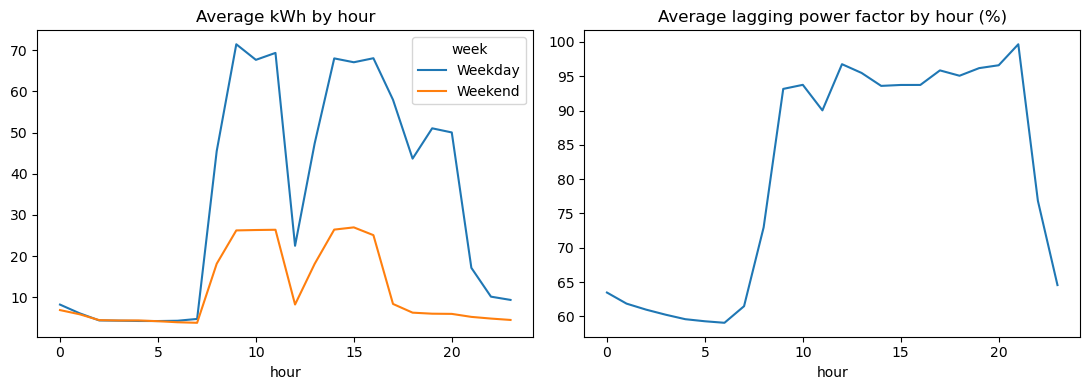

In [5]:
print("Time range:", df["date"].min(), "->", df["date"].max())
print("Missing values:", int(df.isna().sum().sum()))
print("\nMain columns:")
print(df[["kwh", "q_lag", "pf_lag", "co2"]].describe().round(2))
print("\nCorrelation between kWh and CO2:", round(df["kwh"].corr(df["co2"]), 4),
      "(close to 1 = CO2 follows energy, so it is not a separate objective)")
print("\nLoad types:\n", df["load"].value_counts())

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df.groupby(["week", "hour"])["kwh"].mean().unstack(0).plot(ax=ax[0], title="Average kWh by hour")
df.groupby("hour")["pf_lag"].mean().plot(ax=ax[1], title="Average lagging power factor by hour (%)")
plt.tight_layout(); plt.show()

In [6]:
df["kwh_d1"], df["q_d1"] = df["kwh"].shift(96), df["q_lag"].shift(96)
df["kwh_w1"], df["q_w1"] = df["kwh"].shift(672), df["q_lag"].shift(672)
df = df.dropna(subset=["kwh_d1", "q_d1", "kwh_w1", "q_w1"]).reset_index(drop=True)

cutoff = df["date"].min().normalize() + pd.DateOffset(months=9)   # 9 months for training
train = df[df["date"] < cutoff]
test = df[df["date"] >= cutoff]                                   # the rest is never seen in training
print(f"Training rows: {len(train)}   Test rows: {len(test)}   (split at {cutoff.date()})")

Training rows: 26208   Test rows: 8160   (split at 2018-10-08)


target             model   RMSE    MAE    R2
   kwh Linear regression 20.215 13.731 0.607
   kwh     Random forest 19.298 10.588 0.642
   kwh Gradient boosting 18.142 10.262 0.684
 q_lag Linear regression 10.691  7.363 0.571
 q_lag     Random forest 10.267  6.025 0.604
 q_lag Gradient boosting  9.915  5.932 0.631


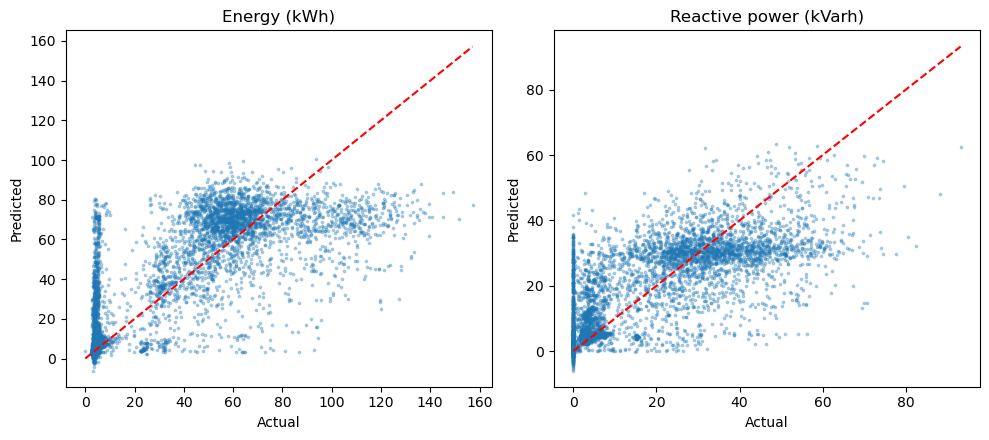

In [7]:
Xtr, Xte = train[FEATURES].values, test[FEATURES].values
rows, final_models = [], {}
for target in ["kwh", "q_lag"]:
    ytr, yte = train[target].values, test[target].values
    candidates = {
        "Linear regression": LinearRegression(),
        "Random forest": RandomForestRegressor(n_estimators=150, min_samples_leaf=3, n_jobs=-1, random_state=0),
        "Gradient boosting": HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=0),
    }
    for name, model in candidates.items():
        model.fit(Xtr, ytr)
        p = model.predict(Xte)
        rows.append({"target": target, "model": name,
                     "RMSE": np.sqrt(mean_squared_error(yte, p)),
                     "MAE": mean_absolute_error(yte, p), "R2": r2_score(yte, p)})
    final_models[target] = candidates["Gradient boosting"]      # the one we use later

metrics = pd.DataFrame(rows).round(3)
metrics.to_csv(f"{OUT_DIR}/forecast_metrics.csv", index=False)
print(metrics.to_string(index=False))
m_e, m_q = final_models["kwh"], final_models["q_lag"]          # energy model, reactive-power model

fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
for a, t, nm in zip(ax, ["kwh", "q_lag"], ["Energy (kWh)", "Reactive power (kVarh)"]):
    p = final_models[t].predict(Xte)
    a.scatter(test[t], p, s=3, alpha=0.3)
    m = max(test[t].max(), p.max())
    a.plot([0, m], [0, m], "r--"); a.set_xlabel("Actual"); a.set_ylabel("Predicted"); a.set_title(nm)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/forecast_actual_vs_pred.png", dpi=130); plt.show()

In [8]:
def plan_metrics(P, Q, C):
    """P, Q: kWh and lagging kVarh of the 96 slots of one day.
    C: array (n_plans, N_BLOCKS) = capacitor setting of every block (kVarh per slot).
    Returns (n_plans, 3): [100 - power factor %, peak apparent power per slot, capacitor size]."""
    c = C[:, BLOCK_IDX]                              # capacitor value in each of the 96 slots
    q_net = np.abs(Q[None, :] - c)                   # reactive power left (leading counts too)
    S = np.sqrt(P[None, :] ** 2 + q_net ** 2) + 1e-9 # apparent power
    pf = 100.0 * P.sum() / S.sum(axis=1)             # power factor of the day (%)
    return np.column_stack([100.0 - pf, S.max(axis=1), C.max(axis=1)])

cmax = float(train["q_lag"].quantile(CMAX_QUANTILE))
print(f"Largest capacitor allowed: {cmax:.1f} kVarh per slot = {cmax * KVA:.0f} kVAr")

Largest capacitor allowed: 57.0 kVarh per slot = 228 kVAr


In [9]:
class CompProblem(Problem):
    """Decision variables: capacitor setting of each 3-hour block. Objectives: see plan_metrics."""
    def __init__(self, P, Q, cmax):
        self.P, self.Q = P, Q
        super().__init__(n_var=N_BLOCKS, n_obj=3, xl=0.0, xu=cmax)

    def _evaluate(self, X, out, *args, **kwargs):
        out["F"] = plan_metrics(self.P, self.Q, X)


def initial_population(n, cmax, rng):
    X = rng.uniform(0, cmax, size=(n, N_BLOCKS))
    X[0] = 0.0          # one plan with no capacitor
    X[1] = cmax         # one plan with the maximum capacitor
    return X


def run_nsga2(problem, cmax, seed, gens=None):
    rng = np.random.default_rng(seed)
    algo = NSGA2(pop_size=POP, sampling=initial_population(POP, cmax, rng),
                 crossover=SBX(prob=0.9, eta=15), mutation=PM(eta=20), eliminate_duplicates=True)
    res = minimize(problem, algo, ("n_gen", gens or GENS), seed=seed, verbose=False)
    if res.F is None:
        return None, None
    return np.atleast_2d(res.F), np.atleast_2d(res.X)


def run_random_search(problem, cmax, seed, n_eval=POP * GENS):
    """Simple comparison method: try many random plans and keep the non-dominated ones."""
    rng = np.random.default_rng(seed)
    X = rng.uniform(0, cmax, size=(n_eval, N_BLOCKS))
    out = {}
    problem._evaluate(X, out)
    F = out["F"]
    idx = NonDominatedSorting().do(F, only_non_dominated_front=True)
    return F[idx], X[idx]


def choose_solution(F_plan):
    """From the Pareto set take the smallest capacitor that reaches TARGET_PF; else the best PF."""
    ok = np.where(100.0 - F_plan[:, 0] >= TARGET_PF)[0]
    if len(ok):
        return int(ok[np.argmin(F_plan[ok, 2])]), True
    return int(np.argmin(F_plan[:, 0])), False


def hypervolume(F, norm):
    if F is None or len(F) == 0:
        return 0.0
    return float(HV(ref_point=REF_POINT)(F / norm))


def best_constant(P, Q, cmax, n=60):
    """Fairer baseline: ONE constant capacitor value for the whole day, chosen to give the best PF
    on the forecast (P, Q here are forecasts). Returns the value in kVarh per slot."""
    grid = np.linspace(0, cmax, n)
    C = np.repeat(grid[:, None], N_BLOCKS, axis=1)
    F = plan_metrics(P, Q, C)
    return float(grid[np.argmin(F[:, 0])])

In [10]:
SAFETY_GRID = [0.6, 0.7, 0.8, 0.9, 1.0]     # 1.0 = trust the forecast fully
N_VAL_DAYS = 20
VAL_GENS = 40                                # shorter NSGA-II run, only used for this choice

# models trained on Jan-Jun ONLY, validated on Jul-Sep (all inside the training months)
val_cut = train["date"].min().normalize() + pd.DateOffset(months=6)
fit_part = train[train["date"] < val_cut]
val_part = train[train["date"] >= val_cut]
m_e_v = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=0)
m_q_v = HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=0)
m_e_v.fit(fit_part[FEATURES].values, fit_part["kwh"].values)
m_q_v.fit(fit_part[FEATURES].values, fit_part["q_lag"].values)

val_groups = {d: g.sort_values("date") for d, g in val_part.groupby(val_part["date"].dt.date) if len(g) == 96}
val_days = sorted(val_groups)
val_pick = np.unique(np.linspace(0, len(val_days) - 1, min(N_VAL_DAYS, len(val_days))).astype(int))

val_rows = []
for s_fac in SAFETY_GRID:
    realised = []
    for i in val_pick:
        g = val_groups[val_days[i]]
        P, Q = g["kwh"].values, g["q_lag"].values
        Xd = g[FEATURES].values
        P_hat = np.clip(m_e_v.predict(Xd), 0, None)
        Q_plan = np.clip(m_q_v.predict(Xd), 0, None) * s_fac
        F, X = run_nsga2(CompProblem(P_hat, Q_plan, cmax), cmax, seed=0, gens=VAL_GENS)
        k, _ = choose_solution(F)
        realised.append(100 - plan_metrics(P, Q, X[k][None, :])[0, 0])      # real PF on the validation day
    val_rows.append({"safety_factor": s_fac, "mean_PF_%": np.mean(realised),
                     "worst_day_PF_%": np.min(realised)})

val_table = pd.DataFrame(val_rows).round(2)
print(val_table.to_string(index=False))
Q_SAFETY = float(val_table.loc[val_table["mean_PF_%"].idxmax(), "safety_factor"])
print(f"\nChosen safety factor (best mean PF on the validation days): {Q_SAFETY}")

 safety_factor  mean_PF_%  worst_day_PF_%
           0.6      84.80           74.12
           0.7      86.80           79.46
           0.8      88.61           79.79
           0.9      89.94           83.23
           1.0      90.72           83.00

Chosen safety factor (best mean PF on the validation days): 1.0


In [11]:
from datetime import timedelta

# average load level of every complete day in the dataset (0 = Light, 1 = Medium, 2 = Maximum)
day_load = {d: g["load_c"].mean() for d, g in df.groupby(df["date"].dt.date) if len(g) == 96}

def load_mismatch(d, today_mean):
    """How different is today's planned load level from yesterday and from last week? (known a day ahead)"""
    y = day_load.get(d - timedelta(days=1))
    w = day_load.get(d - timedelta(days=7))
    if y is None or w is None:
        return np.inf                       # not enough history -> treat as unreliable
    return max(abs(today_mean - y), abs(today_mean - w))

zeros = np.zeros((1, N_BLOCKS))
GUARD_GRID = [0.05, 0.1, 0.15, 0.2, 0.3, 0.4, 0.5, np.inf]   # inf = never use the guard
N_GUARD_DAYS = 60

# uses the validation days and the models from Cell 8b (trained on Jan-Jun only)
guard_pick = np.unique(np.linspace(0, len(val_days) - 1, min(N_GUARD_DAYS, len(val_days))).astype(int))
g_rows = []
for i in guard_pick:
    d = val_days[i]
    g = val_groups[d]
    P, Q = g["kwh"].values, g["q_lag"].values
    Xd = g[FEATURES].values
    P_hat = np.clip(m_e_v.predict(Xd), 0, None)
    Q_plan = np.clip(m_q_v.predict(Xd), 0, None) * Q_SAFETY
    F, X = run_nsga2(CompProblem(P_hat, Q_plan, cmax), cmax, seed=0, gens=VAL_GENS)
    k, _ = choose_solution(F)
    g_rows.append({"day": str(d),
                   "mismatch": load_mismatch(d, g["load_c"].mean()),
                   "pf_none": 100 - plan_metrics(P, Q, zeros)[0, 0],
                   "pf_plan": 100 - plan_metrics(P, Q, X[k][None, :])[0, 0]})
gdf = pd.DataFrame(g_rows)
print(f"Validation days where the plan made PF worse: {int((gdf['pf_plan'] < gdf['pf_none']).sum())} of {len(gdf)}\n")

tab = []
for tau in GUARD_GRID:
    use_plan = gdf["mismatch"] <= tau
    pf = np.where(use_plan, gdf["pf_plan"], gdf["pf_none"])
    tab.append({"threshold": tau, "days_guarded": int((~use_plan).sum()),
                "mean_PF_%": pf.mean(), "worst_day_PF_%": pf.min()})
tab_df = pd.DataFrame(tab).round(3)
print(tab_df.to_string(index=False))

best_row = tab_df.sort_values(["mean_PF_%", "worst_day_PF_%"], ascending=False).iloc[0]
TAU = float(best_row["threshold"])
print(f"\nChosen guard threshold (validation days only): {TAU}")
if np.isinf(TAU):
    print("-> the guard did not help on the validation days, so it will not be used.")

Validation days where the plan made PF worse: 5 of 60

 threshold  days_guarded  mean_PF_%  worst_day_PF_%
      0.05            22     86.339          63.452
      0.10            22     86.339          63.452
      0.15            22     86.339          63.452
      0.20            22     86.339          63.452
      0.30            22     86.339          63.452
      0.40            22     86.339          63.452
      0.50            22     86.339          63.452
       inf             0     89.002          30.808

Chosen guard threshold (validation days only): inf
-> the guard did not help on the validation days, so it will not be used.


In [12]:
groups = {d: g.sort_values("date") for d, g in test.groupby(test["date"].dt.date) if len(g) == 96}
days_all = sorted(groups)
pick = np.unique(np.linspace(0, len(days_all) - 1, min(N_DAYS, len(days_all))).astype(int))
rows, example = [], None
print(f"Evaluating {len(pick)} unseen test days (safety factor {Q_SAFETY}, guard threshold {TAU})...\n")

for i in pick:
    d = days_all[i]
    g = groups[d]
    P, Q = g["kwh"].values, g["q_lag"].values            # ACTUAL measured values
    Xd = g[FEATURES].values
    P_hat = np.clip(m_e.predict(Xd), 0, None)            # AI forecast of energy
    Q_plan = np.clip(m_q.predict(Xd), 0, None) * Q_SAFETY   # AI forecast of reactive power

    # 1) plan with NSGA-II using the FORECAST
    problem = CompProblem(P_hat, Q_plan, cmax)
    base_plan = plan_metrics(P_hat, Q_plan, zeros)[0]
    norm = np.array([max(base_plan[0], 1e-6), base_plan[1], cmax])
    hv_n, hv_r, F_plan, X_plan = [], [], None, None
    for s in range(N_SEEDS):
        Fn, Xn = run_nsga2(problem, cmax, seed=s)
        Fr, _ = run_random_search(problem, cmax, seed=s)
        hv_n.append(hypervolume(Fn, norm)); hv_r.append(hypervolume(Fr, norm))
        if s == 0 and Fn is not None:
            F_plan, X_plan = Fn, Xn
    if F_plan is None:
        print(d, ": no solution, skipped"); continue
    k, target_met = choose_solution(F_plan)
    c_plan = X_plan[k]

    # 2) best constant capacitor baseline (chosen on the same forecast)
    c_const = best_constant(P_hat, Q_plan, cmax)

    # 3) the guard: is today's load pattern similar to yesterday / last week?
    mism = load_mismatch(d, g["load_c"].mean())
    guard_used = bool(mism > TAU)                          # True -> do not compensate today

    # 4) check everything on the ACTUAL measured data
    none = plan_metrics(P, Q, zeros)[0]
    ours = plan_metrics(P, Q, c_plan[None, :])[0]          # AI plan without guard
    const = plan_metrics(P, Q, np.full((1, N_BLOCKS), c_const))[0]
    final = none if guard_used else ours                   # AI plan with guard
    q_left = np.abs(Q - (0 if guard_used else c_plan[BLOCK_IDX]))
    rows.append({
        "day": str(d), "mismatch": mism, "guard_used": guard_used,
        "pf_none_%": 100 - none[0], "pf_const_%": 100 - const[0],
        "pf_nsga2_%": 100 - ours[0], "pf_guard_%": 100 - final[0],
        "pf_planned_%": 100 - F_plan[k, 0],
        "peak_none_kVA": none[1] * KVA, "peak_const_kVA": const[1] * KVA,
        "peak_nsga2_kVA": ours[1] * KVA, "peak_guard_kVA": final[1] * KVA,
        "capacitor_kVAr": c_plan.max() * KVA, "const_kVAr": c_const * KVA,
        "capacitor_guard_kVAr": 0.0 if guard_used else c_plan.max() * KVA,
        "reactive_energy_cut_%": 100 * (1 - q_left.sum() / Q.sum()),
        "target_met_in_plan": target_met,
        "HV_nsga2": float(np.mean(hv_n)), "HV_random": float(np.mean(hv_r)),
    })
    r = rows[-1]
    flag = "GUARD: no compensation" if guard_used else ""
    print(f"{d}: PF {r['pf_none_%']:.1f} -> AI {r['pf_nsga2_%']:.1f}% -> with guard {r['pf_guard_%']:.1f}% "
          f"(best constant {r['pf_const_%']:.1f}%) | mismatch {mism:.2f} {flag}")
    if example is None:
        example = (d, F_plan, k, c_plan, P, Q)

res = pd.DataFrame(rows)
res.to_csv(f"{OUT_DIR}/results_per_day.csv", index=False)
res

Evaluating 30 unseen test days (safety factor 1.0, guard threshold inf)...

2018-10-08: PF 85.5 -> AI 93.6% -> with guard 93.6% (best constant 90.1%) | mismatch 0.83 
2018-10-10: PF 88.3 -> AI 94.7% -> with guard 94.7% (best constant 92.6%) | mismatch 0.00 
2018-10-13: PF 85.0 -> AI 85.5% -> with guard 85.5% (best constant 89.4%) | mismatch 0.00 
2018-10-16: PF 81.6 -> AI 90.8% -> with guard 90.8% (best constant 87.9%) | mismatch 0.00 
2018-10-19: PF 83.3 -> AI 91.2% -> with guard 91.2% (best constant 89.1%) | mismatch 0.00 
2018-10-22: PF 85.4 -> AI 93.1% -> with guard 93.1% (best constant 91.1%) | mismatch 0.83 
2018-10-25: PF 84.2 -> AI 92.6% -> with guard 92.6% (best constant 90.4%) | mismatch 0.00 
2018-10-28: PF 68.0 -> AI 93.3% -> with guard 93.3% (best constant 74.5%) | mismatch 0.83 
2018-10-31: PF 87.3 -> AI 93.2% -> with guard 93.2% (best constant 91.3%) | mismatch 0.00 
2018-11-03: PF 90.6 -> AI 95.8% -> with guard 95.8% (best constant 94.6%) | mismatch 0.00 
2018-11-05: PF

,day,mismatch,guard_used,pf_none_%,pf_const_%,pf_nsga2_%,pf_guard_%,pf_planned_%,peak_none_kVA,peak_const_kVA,peak_nsga2_kVA,peak_guard_kVA,capacitor_kVAr,const_kVAr,capacitor_guard_kVAr,reactive_energy_cut_%,target_met_in_plan,HV_nsga2,HV_random
0,2018-10-08,0.833333,False,85.475825,90.083905,93.649973,93.649973,95.278933,502.154381,489.428808,476.898695,476.898695,96.635495,27.046102,96.635495,41.235675,True,0.089487,0.053930
1,2018-10-10,0.000000,False,88.349757,92.589895,94.671813,94.671813,95.359555,538.088393,528.305444,514.275727,514.275727,122.344015,23.182373,122.344015,42.274081,True,0.105104,0.057422
2,2018-10-13,0.000000,False,85.023225,89.367596,85.478621,85.478621,94.928321,463.374083,454.833955,444.527034,444.527034,76.300452,23.182373,76.300452,19.769681,False,0.084969,0.039510
3,2018-10-16,0.000000,False,81.577734,87.866706,90.840506,90.840506,95.134457,544.779588,533.640486,517.950056,517.950056,77.120175,27.046102,77.120175,35.789162,True,0.092872,0.057687
4,2018-10-19,0.000000,False,83.279565,89.056321,91.193839,91.193839,95.509944,603.376441,587.979206,586.072497,586.072497,79.452399,27.046102,79.452399,36.476244,True,0.101762,0.057991
5,2018-10-22,0.833333,False,85.352904,91.131579,93.112116,93.112116,95.035261,549.389399,536.854531,529.973064,529.973064,76.462285,27.046102,76.462285,44.413993,True,0.099446,0.061348
6,2018-10-25,0.000000,False,84.191363,90.383961,92.598891,92.598891,95.116844,400.547038,383.568666,384.986340,384.986340,60.792475,27.046102,60.792475,38.651646,True,0.092220,0.057533
7,2018-10-28,0.833333,False,67.974589,74.458161,93.267731,93.267731,95.134078,30.716927,22.496089,21.067438,21.067438,23.606396,11.591186,23.606396,64.248256,True,0.140894,0.000000
8,2018-10-31,0.000000,False,87.324472,91.250072,93.199141,93.199141,95.303683,631.626463,621.082274,608.461956,608.461956,75.929960,23.182373,75.929960,30.565360,True,0.108593,0.058760
9,2018-11-03,0.000000,False,90.636600,94.561653,95.835178,95.835178,96.563877,390.241904,384.483623,384.767503,384.767503,21.679445,19.318644,21.679445,27.276954,True,0.075888,0.008414


In [13]:
print(f"SUMMARY OVER {len(res)} UNSEEN TEST DAYS (measured data)")
print(f"Safety factor {Q_SAFETY} | guard threshold {TAU} | days guarded: {int(res['guard_used'].sum())}\n")
print(f"Power factor : none {res['pf_none_%'].mean():.2f}% | best constant {res['pf_const_%'].mean():.2f}% "
      f"| AI plan {res['pf_nsga2_%'].mean():.2f}% | AI plan + guard {res['pf_guard_%'].mean():.2f}%")
print(f"Peak demand  : none {res['peak_none_kVA'].mean():.1f} | best constant {res['peak_const_kVA'].mean():.1f} "
      f"| AI plan {res['peak_nsga2_kVA'].mean():.1f} | AI plan + guard {res['peak_guard_kVA'].mean():.1f} kVA")
print(f"Capacitor    : AI plan {res['capacitor_kVAr'].mean():.1f} | with guard {res['capacitor_guard_kVAr'].mean():.1f} "
      f"| constant {res['const_kVAr'].mean():.1f} kVAr (average)")
print(f"Days with PF >= 90%: none {(res['pf_none_%'] >= 90).mean()*100:.0f}% | constant {(res['pf_const_%'] >= 90).mean()*100:.0f}% "
      f"| AI plan {(res['pf_nsga2_%'] >= 90).mean()*100:.0f}% | AI plan + guard {(res['pf_guard_%'] >= 90).mean()*100:.0f}%")
print(f"Planned PF {res['pf_planned_%'].mean():.2f}% vs realised PF (AI plan) {res['pf_nsga2_%'].mean():.2f}%")

for col, name in [("pf_nsga2_%", "AI plan"), ("pf_guard_%", "AI plan + guard")]:
    worse = res[res[col] < res["pf_none_%"] - 1e-9]
    print(f"\nDAYS WHERE {name.upper()} MADE PF WORSE: {len(worse)} of {len(res)}")
    if len(worse):
        print(worse[["day", "mismatch", "guard_used", "pf_none_%", col]].round(2).to_string(index=False))

def wtest(a, b, label):
    try:
        stat, p = wilcoxon(a, b)
        print(f"{label:50s} p = {p:.4f}  {'(significant)' if p < 0.05 else '(not significant)'}")
    except ValueError:
        print(f"{label}: not possible (identical values)")

print("\nWILCOXON SIGNED-RANK TESTS (paired, per day)")
wtest(res["pf_none_%"], res["pf_guard_%"], "PF: no capacitor vs AI plan + guard")
wtest(res["pf_const_%"], res["pf_guard_%"], "PF: best constant bank vs AI plan + guard")
wtest(res["pf_nsga2_%"], res["pf_guard_%"], "PF: AI plan vs AI plan + guard")
wtest(res["peak_none_kVA"], res["peak_guard_kVA"], "Peak kVA: no capacitor vs AI plan + guard")
wtest(res["peak_const_kVA"], res["peak_guard_kVA"], "Peak kVA: best constant bank vs AI plan + guard")
wtest(res["HV_nsga2"], res["HV_random"], "Hypervolume: NSGA-II vs random search")

SUMMARY OVER 30 UNSEEN TEST DAYS (measured data)
Safety factor 1.0 | guard threshold inf | days guarded: 0

Power factor : none 87.02% | best constant 89.15% | AI plan 91.29% | AI plan + guard 91.29%
Peak demand  : none 386.4 | best constant 376.3 | AI plan 373.7 | AI plan + guard 373.7 kVA
Capacitor    : AI plan 53.3 | with guard 53.3 | constant 23.4 kVAr (average)
Days with PF >= 90%: none 33% | constant 57% | AI plan 77% | AI plan + guard 77%
Planned PF 95.28% vs realised PF (AI plan) 91.29%

DAYS WHERE AI PLAN MADE PF WORSE: 4 of 30
       day  mismatch  guard_used  pf_none_%  pf_nsga2_%
2018-11-29      0.00       False      91.09       89.03
2018-12-10      0.83       False      90.43       89.67
2018-12-25      0.83       False      89.57       81.75
2018-12-31      0.83       False      89.44       60.72

DAYS WHERE AI PLAN + GUARD MADE PF WORSE: 4 of 30
       day  mismatch  guard_used  pf_none_%  pf_guard_%
2018-11-29      0.00       False      91.09       89.03
2018-12-10    

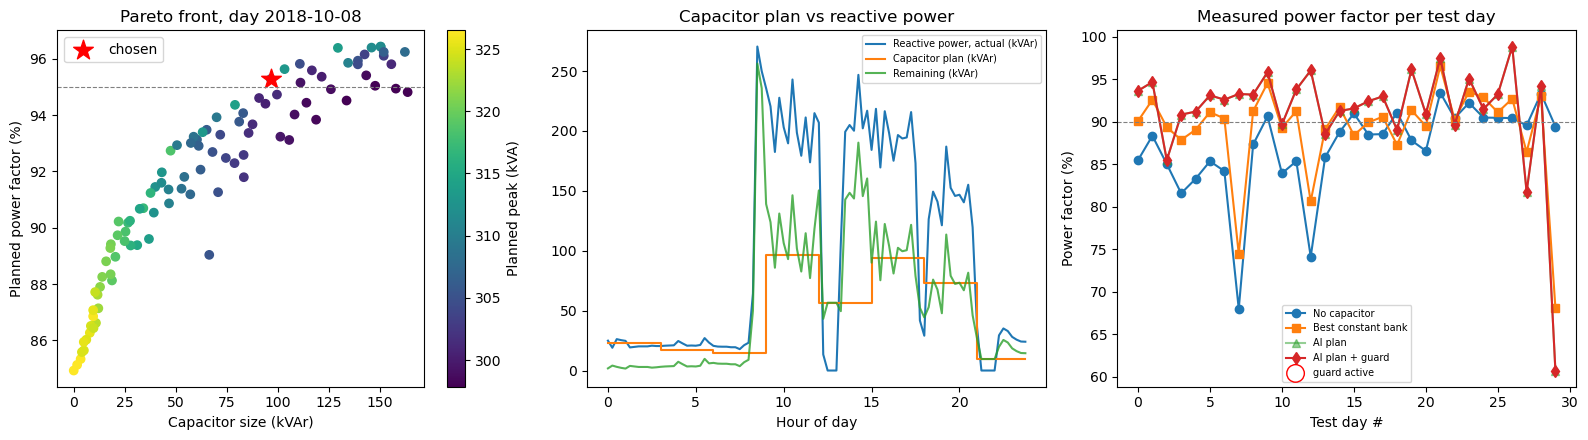

In [14]:
d, F_plan, k, c_plan, P, Q = example
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

sc = ax[0].scatter(F_plan[:, 2] * KVA, 100 - F_plan[:, 0], c=F_plan[:, 1] * KVA, cmap="viridis")
ax[0].scatter(F_plan[k, 2] * KVA, 100 - F_plan[k, 0], c="red", marker="*", s=220, label="chosen")
ax[0].axhline(TARGET_PF, color="grey", ls="--", lw=0.8)
ax[0].set_xlabel("Capacitor size (kVAr)"); ax[0].set_ylabel("Planned power factor (%)")
ax[0].set_title(f"Pareto front, day {d}"); ax[0].legend()
plt.colorbar(sc, ax=ax[0], label="Planned peak (kVA)")

t = np.arange(96) / 4
ax[1].plot(t, Q * KVA, label="Reactive power, actual (kVAr)")
ax[1].step(t, c_plan[BLOCK_IDX] * KVA, where="post", label="Capacitor plan (kVAr)")
ax[1].plot(t, np.abs(Q - c_plan[BLOCK_IDX]) * KVA, label="Remaining (kVAr)", alpha=0.8)
ax[1].set_xlabel("Hour of day"); ax[1].set_title("Capacitor plan vs reactive power"); ax[1].legend(fontsize=7)

x = np.arange(len(res))
ax[2].plot(x, res["pf_none_%"], "o-", label="No capacitor")
ax[2].plot(x, res["pf_const_%"], "s-", label="Best constant bank")
ax[2].plot(x, res["pf_nsga2_%"], "^-", alpha=0.5, label="AI plan")
ax[2].plot(x, res["pf_guard_%"], "d-", label="AI plan + guard")
gd = res.index[res["guard_used"]]
ax[2].scatter(gd, res.loc[gd, "pf_guard_%"], s=160, facecolors="none", edgecolors="red", label="guard active")
ax[2].axhline(90, color="grey", ls="--", lw=0.8)
ax[2].set_xlabel("Test day #"); ax[2].set_ylabel("Power factor (%)")
ax[2].set_title("Measured power factor per test day"); ax[2].legend(fontsize=7)

plt.tight_layout(); plt.savefig(f"{OUT_DIR}/results_overview.png", dpi=130); plt.show()

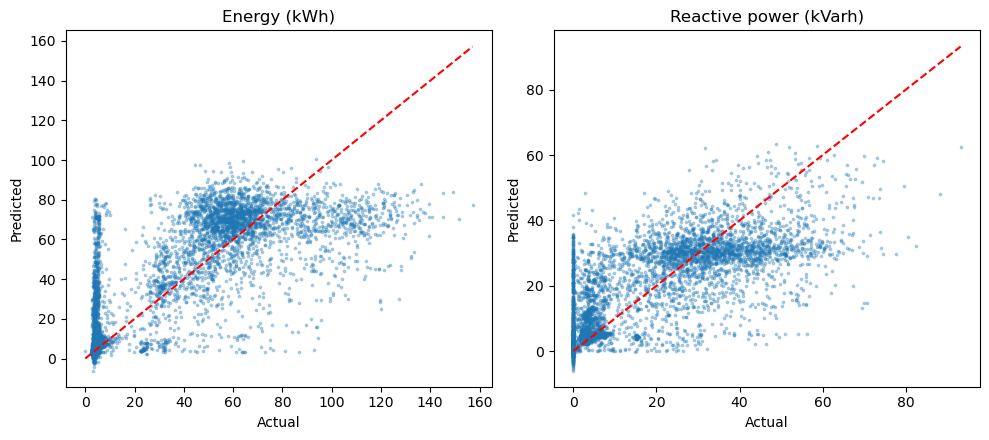

RQ1 answer: R2 = 0.684 (energy) and 0.631 (reactive power) on unseen months.


In [15]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
for a, t, nm in zip(ax, ["kwh", "q_lag"], ["Energy (kWh)", "Reactive power (kVarh)"]):
    p = final_models[t].predict(test[FEATURES].values)
    a.scatter(test[t], p, s=3, alpha=0.3)
    m = max(test[t].max(), p.max())
    a.plot([0, m], [0, m], "r--"); a.set_xlabel("Actual"); a.set_ylabel("Predicted"); a.set_title(nm)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_5_09_forecast_actual_vs_pred.png", dpi=130); plt.show()
gb = metrics[metrics["model"] == "Gradient boosting"].set_index("target")["R2"]
print(f"RQ1 answer: R2 = {gb['kwh']:.3f} (energy) and {gb['q_lag']:.3f} (reactive power) on unseen months.")

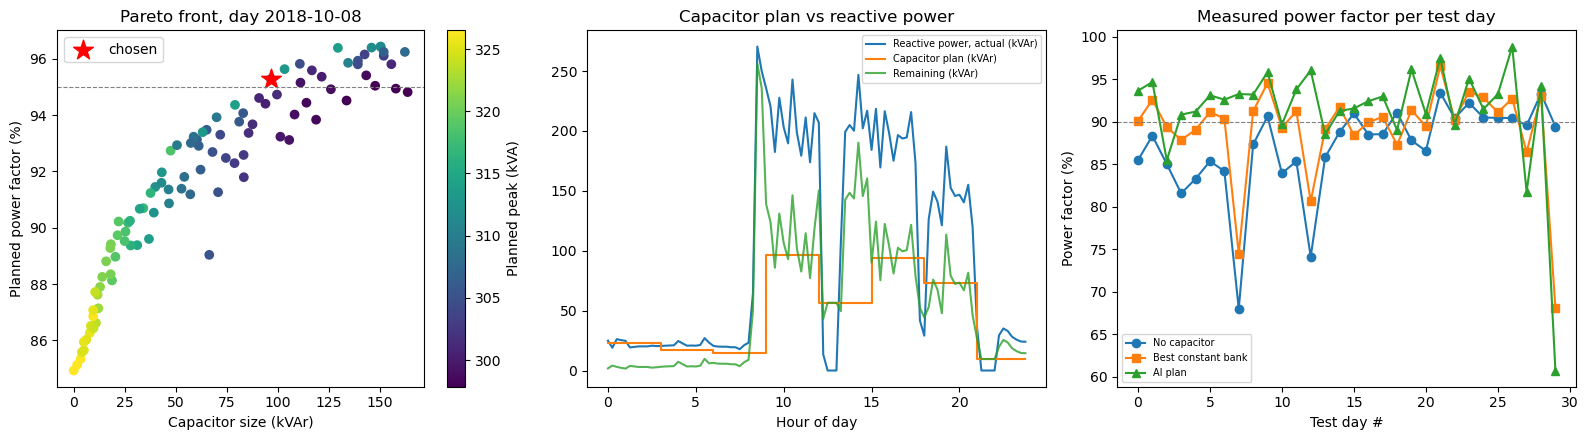

RQ2 answer: mean PF 87.02% -> 91.29%, peak 386.4 -> 373.7 kVA; PF better on 26 of 30 days


In [16]:
d, F_plan, k, c_plan, P, Q = example
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
sc = ax[0].scatter(F_plan[:, 2] * KVA, 100 - F_plan[:, 0], c=F_plan[:, 1] * KVA, cmap="viridis")
ax[0].scatter(F_plan[k, 2] * KVA, 100 - F_plan[k, 0], c="red", marker="*", s=220, label="chosen")
ax[0].axhline(TARGET_PF, color="grey", ls="--", lw=0.8)
ax[0].set_xlabel("Capacitor size (kVAr)"); ax[0].set_ylabel("Planned power factor (%)")
ax[0].set_title(f"Pareto front, day {d}"); ax[0].legend()
plt.colorbar(sc, ax=ax[0], label="Planned peak (kVA)")
t = np.arange(96) / 4
ax[1].plot(t, Q * KVA, label="Reactive power, actual (kVAr)")
ax[1].step(t, c_plan[BLOCK_IDX] * KVA, where="post", label="Capacitor plan (kVAr)")
ax[1].plot(t, np.abs(Q - c_plan[BLOCK_IDX]) * KVA, label="Remaining (kVAr)", alpha=0.8)
ax[1].set_xlabel("Hour of day"); ax[1].set_title("Capacitor plan vs reactive power"); ax[1].legend(fontsize=7)
x = np.arange(len(res))
ax[2].plot(x, res["pf_none_%"], "o-", label="No capacitor")
ax[2].plot(x, res["pf_const_%"], "s-", label="Best constant bank")
ax[2].plot(x, res["pf_nsga2_%"], "^-", label="AI plan")
ax[2].axhline(90, color="grey", ls="--", lw=0.8)
ax[2].set_xlabel("Test day #"); ax[2].set_ylabel("Power factor (%)")
ax[2].set_title("Measured power factor per test day"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_5_10_results_overview.png", dpi=130); plt.show()
print(f"RQ2 answer: mean PF {res['pf_none_%'].mean():.2f}% -> {res['pf_nsga2_%'].mean():.2f}%, "
      f"peak {res['peak_none_kVA'].mean():.1f} -> {res['peak_nsga2_kVA'].mean():.1f} kVA; "
      f"PF better on {(res['pf_nsga2_%'] > res['pf_none_%']).sum()} of {len(res)} days")

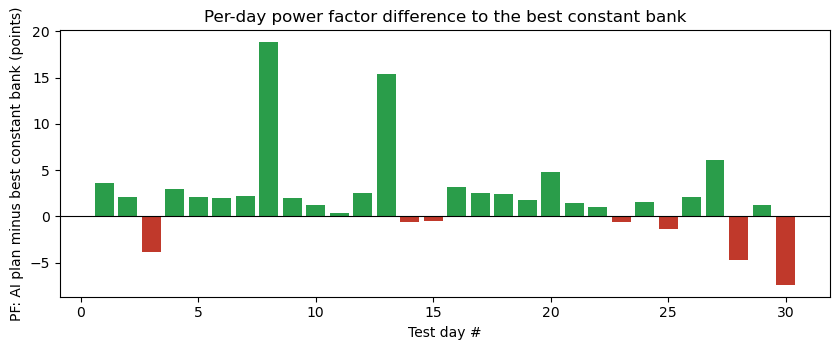

RQ3 answer: AI plan better on 23 of 30 days; mean PF 91.29% vs 89.15%; capacitor 53.3 vs 23.4 kVAr


In [17]:
diff = res["pf_nsga2_%"] - res["pf_const_%"]
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.bar(np.arange(1, len(res) + 1), diff, color=["#2a9d4a" if v >= 0 else "#c0392b" for v in diff])
ax.axhline(0, color="k", lw=0.8)
ax.set_xlabel("Test day #"); ax.set_ylabel("PF: AI plan minus best constant bank (points)")
ax.set_title("Per-day power factor difference to the best constant bank")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_5_11_vs_constant_bank.png", dpi=170); plt.show()
print(f"RQ3 answer: AI plan better on {(diff > 0).sum()} of {len(res)} days; mean PF "
      f"{res['pf_nsga2_%'].mean():.2f}% vs {res['pf_const_%'].mean():.2f}%; "
      f"capacitor {res['capacitor_kVAr'].mean():.1f} vs {res['const_kVAr'].mean():.1f} kVAr")

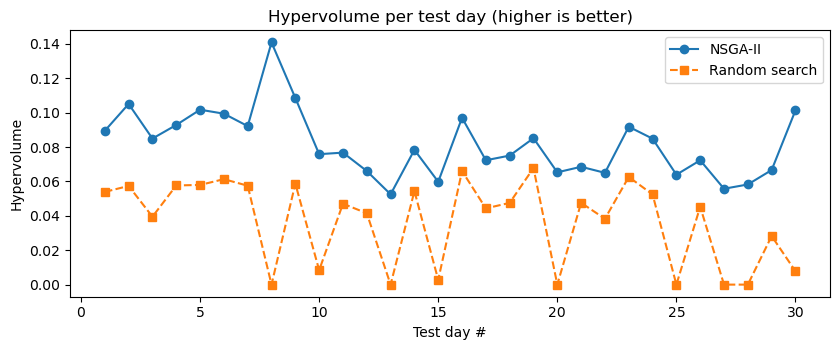

RQ4 answer: NSGA-II higher on 30 of 30 days; mean 0.082 vs 0.037


In [18]:
x = np.arange(1, len(res) + 1)
fig, ax = plt.subplots(figsize=(8.5, 3.6))
ax.plot(x, res["HV_nsga2"], "o-", label="NSGA-II"); ax.plot(x, res["HV_random"], "s--", label="Random search")
ax.set_xlabel("Test day #"); ax.set_ylabel("Hypervolume"); ax.set_title("Hypervolume per test day (higher is better)"); ax.legend()
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_5_12_hypervolume.png", dpi=170); plt.show()
print(f"RQ4 answer: NSGA-II higher on {(res['HV_nsga2'] > res['HV_random']).sum()} of {len(res)} days; "
      f"mean {res['HV_nsga2'].mean():.3f} vs {res['HV_random'].mean():.3f}")

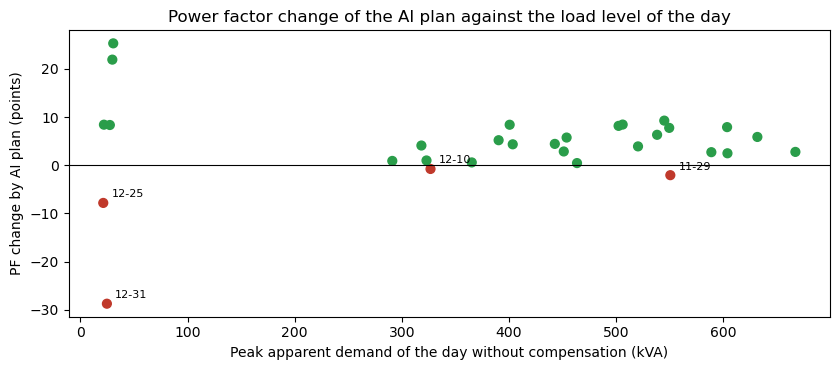

       day  pf_none_%  pf_nsga2_%  peak_none_kVA
2018-11-29       91.1        89.0          550.4
2018-12-10       90.4        89.7          326.7
2018-12-25       89.6        81.8           21.4
2018-12-31       89.4        60.7           24.8


In [19]:
chg = res["pf_nsga2_%"] - res["pf_none_%"]
fig, ax = plt.subplots(figsize=(8.5, 3.8))
ax.scatter(res["peak_none_kVA"], chg, c=["#2a9d4a" if v >= 0 else "#c0392b" for v in chg], s=40)
ax.axhline(0, color="k", lw=0.8)
for i in res.index[chg < 0]:
    ax.annotate(res["day"][i][5:], (res["peak_none_kVA"][i], chg[i]), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xlabel("Peak apparent demand of the day without compensation (kVA)"); ax.set_ylabel("PF change by AI plan (points)")
ax.set_title("Power factor change of the AI plan against the load level of the day")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_5_13_failure_days.png", dpi=170); plt.show()
print(res.loc[chg < 0, ["day", "pf_none_%", "pf_nsga2_%", "peak_none_kVA"]].round(1).to_string(index=False))